# Analisis Data E-Commerce Olist: Optimasi GMV dari Traffic dan Logistik

Proyek lomba Data Analytics TechFest HIMTI BINUS (tema Business) dengan dataset publik Olist (Brazilian E-Commerce dan Marketing Funnel).

Fokus analisis:
1. **Marketing**: Dari mana dapet sellernya dan channel mana yang paling efektif
2. **Logistik**: Seberapa ngaruh keterlambatan pengiriman ke review score
3. **Pelanggan**: Segmentasi RFM, cohort retensi, dan model prediktif
4. **Forecasting**: Peramalan tren GMV bulanan

Dataset diletakkan di folder `data/` (lihat `data/README.md`).

## 1. Setup: Import Library

In [1]:
# ===== BAGIAN 1: SETUP =====

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import random
from pathlib import Path
from datetime import datetime
from scipy.stats import f_oneway
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

print(f'Setup selesai. Random seed = {RANDOM_STATE}')

Setup selesai. Random seed = 42


In [2]:
# ===== SET PATH DATASET =====
# Path relatif dari folder notebooks/ ke folder data/

DATA_DIR = Path('..') / 'data'

path_eco = DATA_DIR / 'ecommerce_olist'
path_mkt = DATA_DIR / 'marketing_funnel'

# Verifikasi path
if not path_eco.exists():
    print(f'ERROR: Path tidak ditemukan: {path_eco.as_posix()}')
    print('Unduh dataset dan letakkan sesuai petunjuk di data/README.md.')
else:
    print(f'Path OK: {path_eco.as_posix()}')
    print(f'Path OK: {path_mkt.as_posix()}')

Path OK: ../data/ecommerce_olist
Path OK: ../data/marketing_funnel


## 2. Loading Data

In [3]:
# ===== BAGIAN 2: LOAD DATA =====

df_mql = pd.read_csv(path_mkt / 'olist_marketing_qualified_leads_dataset.csv')
df_closed = pd.read_csv(path_mkt / 'olist_closed_deals_dataset.csv')
df_orders = pd.read_csv(path_eco / 'olist_orders_dataset.csv')
df_items = pd.read_csv(path_eco / 'olist_order_items_dataset.csv')
df_payments = pd.read_csv(path_eco / 'olist_order_payments_dataset.csv')
df_reviews = pd.read_csv(path_eco / 'olist_order_reviews_dataset.csv')
df_customers = pd.read_csv(path_eco / 'olist_customers_dataset.csv')
df_products = pd.read_csv(path_eco / 'olist_products_dataset.csv')
df_sellers = pd.read_csv(path_eco / 'olist_sellers_dataset.csv')

print('Semua dataset berhasil di-load!')
print(f'Orders: {df_orders.shape}, Items: {df_items.shape}')
print(f'Payments: {df_payments.shape}, Reviews: {df_reviews.shape}')
print(f'Customers: {df_customers.shape}, Products: {df_products.shape}')
print(f'Sellers: {df_sellers.shape}, MQL: {df_mql.shape}, Closed: {df_closed.shape}')

Semua dataset berhasil di-load!
Orders: (99441, 8), Items: (112650, 7)
Payments: (103886, 5), Reviews: (99224, 7)
Customers: (99441, 5), Products: (32951, 9)
Sellers: (3095, 4), MQL: (8000, 4), Closed: (842, 14)


## 3. Data Understanding

Cek missing values dan statistik dasar.

In [4]:
# Cek missing values semua tabel
for nama, df in [('Orders', df_orders), ('Items', df_items), ('Payments', df_payments),
                 ('Reviews', df_reviews), ('Customers', df_customers), ('Products', df_products)]:
    missing = df.isnull().sum()
    total_miss = missing.sum()
    if total_miss > 0:
        print(f'{nama}: {total_miss} missing values')
        print(missing[missing > 0].to_string())
    else:
        print(f'{nama}: Tidak ada missing value')

Orders: 4908 missing values
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
Items: Tidak ada missing value
Payments: Tidak ada missing value
Reviews: 145903 missing values
review_comment_title      87656
review_comment_message    58247
Customers: Tidak ada missing value
Products: 2448 missing values
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2


In [5]:
print('=== Statistik Orders ===')
print(df_orders.describe(include='all'))

=== Statistik Orders ===


                                order_id                       customer_id  \
count                              99441                             99441   
unique                             99441                             99441   
top     e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
freq                                   1                                 1   

       order_status order_purchase_timestamp    order_approved_at  \
count         99441                    99441                99281   
unique            8                    98875                90733   
top       delivered      2018-03-31 15:08:21  2018-02-27 04:31:10   
freq          96478                        3                    9   

       order_delivered_carrier_date order_delivered_customer_date  \
count                         97658                         96476   
unique                        81018                         95664   
top             2018-05-09 15:48:00           2018-05-14

## 4. Data Cleaning

Validasi data + penanganan anomali.

In [6]:
# Step 1: Konversi tanggal
df_orders['order_purchase_timestamp'] = pd.to_datetime(df_orders['order_purchase_timestamp'])
df_orders['order_delivered_customer_date'] = pd.to_datetime(df_orders['order_delivered_customer_date'])
df_orders['order_estimated_delivery_date'] = pd.to_datetime(df_orders['order_estimated_delivery_date'])
print('Tanggal berhasil dikonversi')

# Step 2: Hitung delivery delay
df_orders['delivery_delay_days'] = (
    df_orders['order_delivered_customer_date'] - df_orders['order_estimated_delivery_date']
).dt.days
df_orders['is_late'] = df_orders['delivery_delay_days'] > 0

print(f'Rata-rata delay: {df_orders["delivery_delay_days"].mean():.1f} hari')
print(f'Persentase telat: {df_orders["is_late"].mean()*100:.1f}%')

# Step 3: Validasi items
print(f'Min price: {df_items["price"].min():.2f}')
print(f'Max price: {df_items["price"].max():.2f}')
assert df_items['price'].min() >= 0, 'Ada harga negatif!'
print('Tidak ada harga negatif. Valid!')

Tanggal berhasil dikonversi
Rata-rata delay: -11.9 hari
Persentase telat: 6.6%
Min price: 0.85
Max price: 6735.00
Tidak ada harga negatif. Valid!


## 5. Merge Data untuk Analisis

In [7]:
# Gabungkan orders + payments + customers + items
df_gmv = df_orders.merge(df_payments, on='order_id', how='left')
df_gmv = df_gmv.merge(df_customers, on='customer_id', how='left')
df_gmv = df_gmv.merge(df_items[['order_id', 'price', 'freight_value']], on='order_id', how='left')

# GMV = price + freight
df_gmv['gmv'] = df_gmv['price'] + df_gmv['freight_value'].fillna(0)

# Filter hanya order delivered
df_gmv_done = df_gmv[df_gmv['order_status'] == 'delivered'].copy()

print(f'Total order: {len(df_gmv):,}')
print(f'Order delivered: {len(df_gmv_done):,}')
print(f'Total GMV: {df_gmv_done["gmv"].sum():,.0f}')
print(f'Rata-rata GMV per order: {df_gmv_done["gmv"].mean():,.0f}')

Total order: 118,434
Order delivered: 115,038
Total GMV: 16,114,163
Rata-rata GMV per order: 140


---
# FOKUS 1: Marketing - Analisis Sumber Seller

**Pertanyaan:** Dari mana asal seller? Channel mana yang paling efektif?

In [8]:
print('=== Sumber MQL ===')
origin_counts = df_mql['origin'].value_counts()
print(origin_counts)
print()
print('=== Persentase ===')
pct = (origin_counts / origin_counts.sum() * 100).round(1)
print(pct.astype(str) + '%')

=== Sumber MQL ===
origin
organic_search       2296
paid_search          1586
social               1350
unknown              1099
direct_traffic        499
email                 493
referral              284
other                 150
display               118
other_publicities      65
Name: count, dtype: int64

=== Persentase ===
origin
organic_search       28.9%
paid_search          20.0%
social               17.0%
unknown              13.8%
direct_traffic        6.3%
email                 6.2%
referral              3.6%
other                 1.9%
display               1.5%
other_publicities     0.8%
Name: count, dtype: str


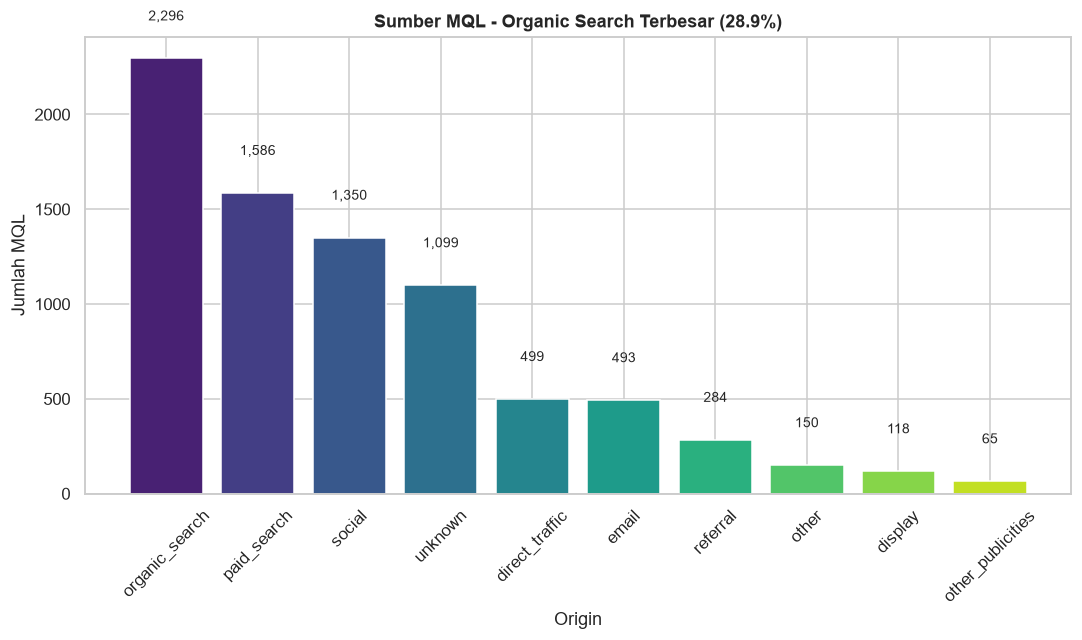

INSIGHT 1: Organic search sumber MQL terbesar (28.9%), disusul paid search (20.0%) dan social (17.0%).
Rekomendasi: SEO tetap jadi sumber lead utama; paid search jangan dipotong karena konversinya setara (lihat chart berikutnya).


In [9]:
plt.figure(figsize=(10, 6))
bars = plt.bar(origin_counts.index, origin_counts.values, color=sns.color_palette('viridis', len(origin_counts)))
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
             f'{bar.get_height():,}', ha='center', fontsize=9)
plt.title('Sumber MQL - Organic Search Terbesar (28.9%)', fontweight='bold')
plt.xlabel('Origin')
plt.ylabel('Jumlah MQL')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('INSIGHT 1: Organic search sumber MQL terbesar (28.9%), disusul paid search (20.0%) dan social (17.0%).')
print('Rekomendasi: SEO tetap jadi sumber lead utama; paid search jangan dipotong karena konversinya setara (lihat chart berikutnya).')

In [10]:
df_mkt = df_mql.merge(df_closed, on='mql_id', how='left')
df_mkt['is_closed'] = df_mkt['seller_id'].notna()

conversion = df_mkt.groupby('origin')['is_closed'].agg(['count', 'sum'])
conversion['conversion_rate'] = (conversion['sum'] / conversion['count'] * 100).round(1)
conversion = conversion.sort_values('conversion_rate', ascending=False)

print('=== Conversion Rate per Origin ===')
print(conversion[['conversion_rate']])

=== Conversion Rate per Origin ===
                   conversion_rate
origin                            
unknown                       16.3
paid_search                   12.3
organic_search                11.8
direct_traffic                11.2
referral                       8.5
social                         5.6
display                        5.1
other_publicities              4.6
email                          3.0
other                          2.7


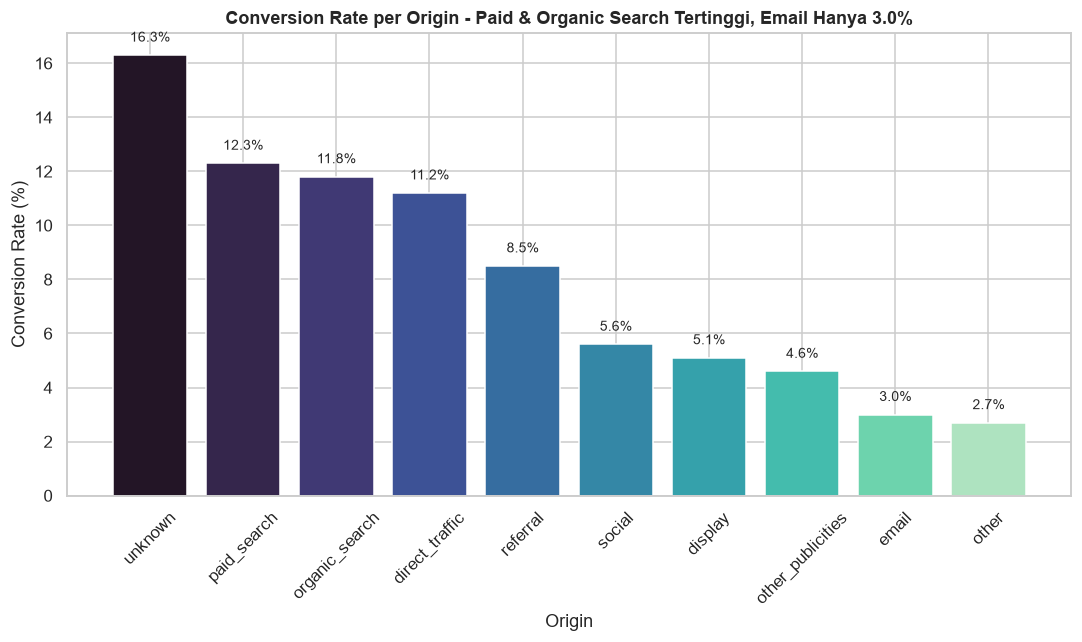

INSIGHT 2: Di luar "unknown" (16.3%, sumber tidak tercatat), konversi tertinggi ada di paid search (12.3%),
organic search (11.8%), dan direct traffic (11.2%). Email hanya 3.0% dan social 5.6% walau volume social 17.0%.
Rekomendasi: Fokuskan akuisisi seller ke search (organic + paid), evaluasi ulang email dan social,
dan perbaiki pencatatan origin supaya porsi "unknown" berkurang.


In [11]:
plt.figure(figsize=(10, 6))
bars = plt.bar(conversion.index, conversion['conversion_rate'],
                color=sns.color_palette('mako', len(conversion)))
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.1f}%', ha='center', fontsize=9)
plt.title('Conversion Rate per Origin - Paid & Organic Search Tertinggi, Email Hanya 3.0%', fontweight='bold')
plt.xlabel('Origin')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('INSIGHT 2: Di luar "unknown" (16.3%, sumber tidak tercatat), konversi tertinggi ada di paid search (12.3%),')
print('organic search (11.8%), dan direct traffic (11.2%). Email hanya 3.0% dan social 5.6% walau volume social 17.0%.')
print('Rekomendasi: Fokuskan akuisisi seller ke search (organic + paid), evaluasi ulang email dan social,')
print('dan perbaiki pencatatan origin supaya porsi "unknown" berkurang.')

---
# FOKUS 2: Logistik - Dampak Keterlambatan ke Review

**Pertanyaan:** Apakah pengiriman telat mempengaruhi review score?

In [12]:
df_log = df_orders.merge(df_reviews, on='order_id', how='inner')
df_log = df_log.merge(df_items[['order_id', 'price', 'freight_value']], on='order_id', how='left')
df_log['gmv'] = df_log['price'] + df_log['freight_value'].fillna(0)
df_log = df_log[df_log['order_status'] == 'delivered'].copy()

print(f'Data: {len(df_log):,} rows')
print(f'Rata-rata review score: {df_log["review_score"].mean():.2f}')
print(f'Persentase telat: {df_log["is_late"].mean()*100:.1f}%')

Data: 110,013 rows
Rata-rata review score: 4.08
Persentase telat: 6.5%


In [13]:
# ANOVA: tepat waktu vs telat
tepat = df_log[~df_log['is_late']]['review_score']
telat = df_log[df_log['is_late']]['review_score']

print(f'Review score (tepat waktu): {tepat.mean():.2f}')
print(f'Review score (telat): {telat.mean():.2f}')
print(f'Selisih: {tepat.mean() - telat.mean():.2f}')

f_stat, p_val = f_oneway(tepat, telat)
print(f'\nANOVA: F={f_stat:.3f}, p-value={p_val:.4f}')
if p_val < 0.05:
    print('Kesimpulan: Perbedaan SIGNIFIKAN (p < 0.05). Pengiriman telat menurunkan review.')

Review score (tepat waktu): 4.21
Review score (telat): 2.26
Selisih: 1.95

ANOVA: F=15964.401, p-value=0.0000
Kesimpulan: Perbedaan SIGNIFIKAN (p < 0.05). Pengiriman telat menurunkan review.


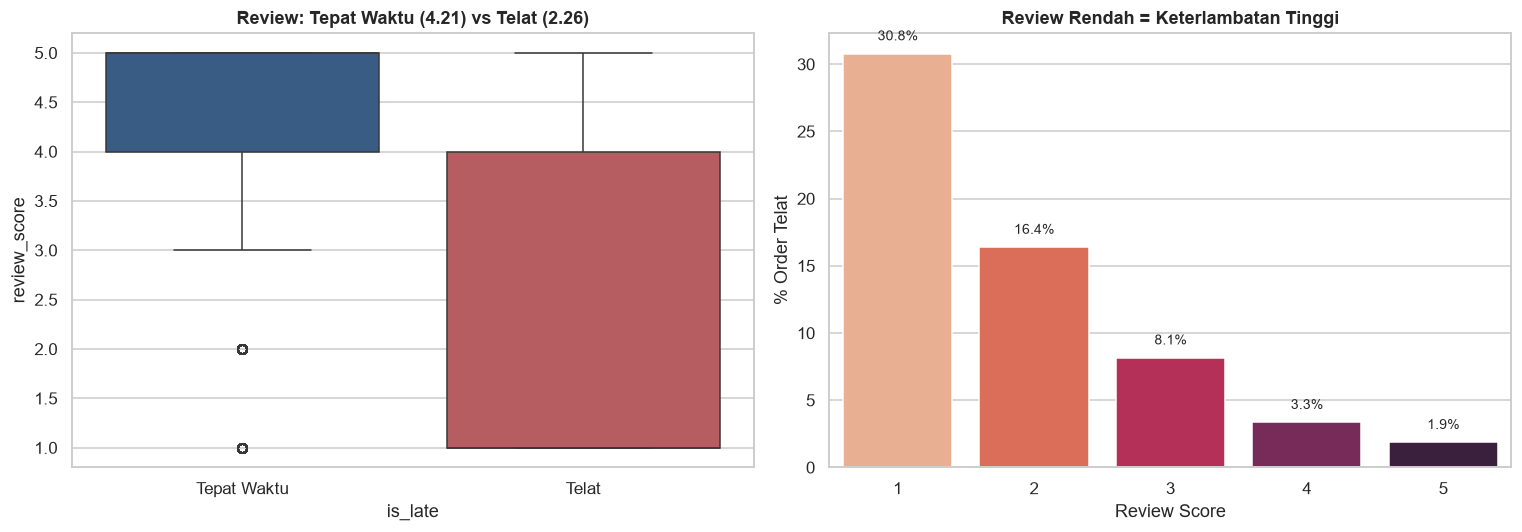

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_log, x='is_late', y='review_score', ax=axes[0],
            palette=['#2b5c8f', '#c44e52'])
axes[0].set_xticklabels(['Tepat Waktu', 'Telat'])
axes[0].set_title(f'Review: Tepat Waktu ({tepat.mean():.2f}) vs Telat ({telat.mean():.2f})', fontweight='bold')

late_pct = df_log.groupby('review_score')['is_late'].mean().mul(100).reset_index()
sns.barplot(data=late_pct, x='review_score', y='is_late', ax=axes[1], palette='rocket_r')
axes[1].set_title('Review Rendah = Keterlambatan Tinggi', fontweight='bold')
axes[1].set_xlabel('Review Score')
axes[1].set_ylabel('% Order Telat')
for i, v in enumerate(late_pct['is_late']):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [15]:
print('INSIGHT 3: Pengiriman telat MENURUNKAN review score signifikan (p<0.05).')
print('Review 1 memiliki tingkat keterlambatan tertinggi.')
print('Rekomendasi: Prioritaskan logistik untuk order high-value.')

INSIGHT 3: Pengiriman telat MENURUNKAN review score signifikan (p<0.05).
Review 1 memiliki tingkat keterlambatan tertinggi.
Rekomendasi: Prioritaskan logistik untuk order high-value.


---
# FOKUS 3: RFM Segmentation

**Pertanyaan:** Siapa customer terbaik?

In [16]:
df_rfm = df_gmv_done.copy()
today = df_rfm['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

recency = df_rfm.groupby('customer_unique_id')['order_purchase_timestamp'].max().reset_index()
recency['recency_days'] = (today - recency['order_purchase_timestamp']).dt.days

frequency = df_rfm.groupby('customer_unique_id')['order_id'].nunique().reset_index()
frequency.columns = ['customer_unique_id', 'frequency']

monetary = df_rfm.groupby('customer_unique_id')['gmv'].sum().reset_index()
monetary.columns = ['customer_unique_id', 'monetary']

rfm = recency.merge(frequency, on='customer_unique_id').merge(monetary, on='customer_unique_id')
print(f'RFM table: {rfm.shape}')
print(rfm.describe().round(1))

RFM table: (93358, 5)
         order_purchase_timestamp  recency_days  frequency  monetary
count                       93358       93358.0    93358.0   93358.0
mean   2018-01-04 03:47:36.045363         237.9        1.0     172.6
min           2016-09-15 12:16:38           1.0        1.0      10.1
25%           2017-09-17 18:25:15         114.0        1.0      64.0
50%    2018-01-23 00:12:12.500000         219.0        1.0     110.4
75%    2018-05-07 17:22:34.750000         346.0        1.0     187.9
max           2018-08-29 15:00:37         714.0       15.0   13664.1
std                           NaN         152.6        0.2     257.8


In [17]:
rfm['R_score'] = pd.qcut(rfm['recency_days'], q=5, labels=[5,4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1,2,3,4,5])
rfm['M_score'] = pd.qcut(rfm['monetary'], q=5, labels=[1,2,3,4,5])

def get_segment(row):
    if row['R_score'] >= 4 and row['F_score'] >= 4:
        return 'Champions'
    elif row['R_score'] >= 4 and row['F_score'] >= 2:
        return 'Loyal'
    elif row['R_score'] >= 4 and row['F_score'] == 1:
        return 'New Customers'
    elif row['R_score'] <= 2 and row['F_score'] >= 4:
        return 'At Risk'
    elif row['R_score'] == 1 and row['F_score'] == 1:
        return 'Lost'
    elif row['R_score'] <= 2 and row['F_score'] <= 2:
        return 'Hibernating'
    else:
        return 'Need Attention'

rfm['segment'] = rfm.apply(get_segment, axis=1)

print('=== Distribusi Segmen ===')
seg_counts = rfm['segment'].value_counts()
print(seg_counts)
print('\n=== Rata-rata Monetary per Segmen ===')
print(rfm.groupby('segment')['monetary'].mean().sort_values(ascending=False).round(0).astype(int))

=== Distribusi Segmen ===
segment
Need Attention    26136
Loyal             14993
Champions         14961
At Risk           14803
Hibernating       11159
New Customers      7479
Lost               3827
Name: count, dtype: int64

=== Rata-rata Monetary per Segmen ===
segment
Champions         184
At Risk           180
Loyal             171
New Customers     171
Hibernating       171
Lost              171
Need Attention    165
Name: monetary, dtype: int64


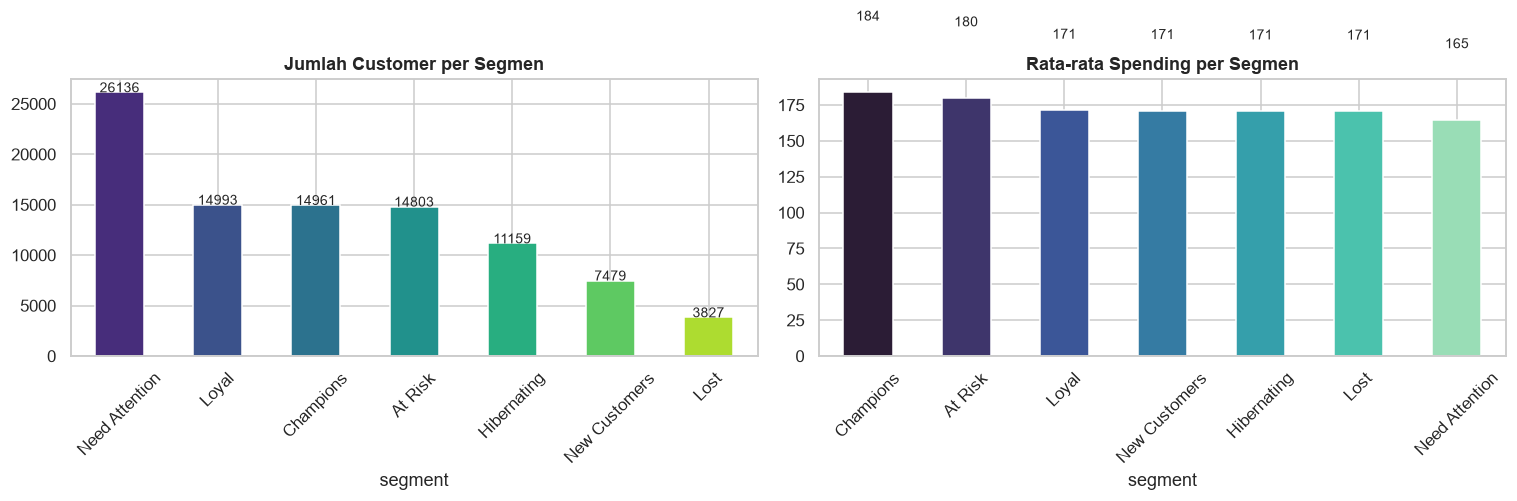

INSIGHT 4: Champions punya rata-rata spending tertinggi (184), tapi selisihnya tipis dibanding segmen lain (165-180).
Catatan: hampir semua customer hanya 1 order (kuartil 75% frequency = 1), jadi F_score lebih banyak ditentukan
urutan baris (rank method="first"). Segmen sebaiknya dibaca terutama dari Recency dan Monetary.
Rekomendasi: Program loyalitas untuk Champions, reaktivasi untuk At Risk, dan dorong order kedua.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

seg_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('viridis', len(seg_counts)))
axes[0].set_title('Jumlah Customer per Segmen', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(seg_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontsize=9)

seg_revenue = rfm.groupby('segment')['monetary'].mean().sort_values(ascending=False)
seg_revenue.plot(kind='bar', ax=axes[1], color=sns.color_palette('mako', len(seg_revenue)))
axes[1].set_title('Rata-rata Spending per Segmen', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(seg_revenue.values):
    axes[1].text(i, v + 50, f'{v:.0f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print('INSIGHT 4: Champions punya rata-rata spending tertinggi (184), tapi selisihnya tipis dibanding segmen lain (165-180).')
print('Catatan: hampir semua customer hanya 1 order (kuartil 75% frequency = 1), jadi F_score lebih banyak ditentukan')
print('urutan baris (rank method="first"). Segmen sebaiknya dibaca terutama dari Recency dan Monetary.')
print('Rekomendasi: Program loyalitas untuk Champions, reaktivasi untuk At Risk, dan dorong order kedua.')

## Cohort Analysis - Retention Rate

In [19]:
df_cohort = df_gmv_done.copy()
df_cohort['order_month'] = df_cohort['order_purchase_timestamp'].dt.to_period('M')

cohort = df_cohort.groupby('customer_unique_id')['order_month'].min().reset_index()
cohort.columns = ['customer_unique_id', 'cohort_month']
df_cohort = df_cohort.merge(cohort, on='customer_unique_id')
df_cohort['month_offset'] = (df_cohort['order_month'] - df_cohort['cohort_month']).apply(lambda x: x.n)

cohort_data = df_cohort.groupby(['cohort_month', 'month_offset'])['customer_unique_id'].nunique().reset_index()
cohort_data['total_customers'] = cohort_data.groupby('cohort_month')['customer_unique_id'].transform('max')
cohort_data['retention'] = (cohort_data['customer_unique_id'] / cohort_data['total_customers']) * 100

cohort_pivot = cohort_data.pivot_table(index='cohort_month', columns='month_offset', values='retention')

print('=== Cohort Retention (%) ===')
print(cohort_pivot.round(1))

=== Cohort Retention (%) ===
month_offset     0      1    2    3    4    5    6    7    8    9    10   11  \
cohort_month                                                                   
2016-09       100.0    NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN   
2016-10       100.0    NaN  NaN  NaN  NaN  NaN  0.4  NaN  NaN  0.4  NaN  0.4   
2016-12       100.0  100.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN   
2017-01       100.0    0.3  0.3  0.1  0.4  0.1  0.4  0.1  0.1  NaN  0.4  0.1   
2017-02       100.0    0.2  0.3  0.1  0.4  0.1  0.2  0.2  0.1  0.2  0.1  0.3   
2017-03       100.0    0.4  0.4  0.4  0.4  0.2  0.2  0.3  0.3  0.1  0.4  0.1   
2017-04       100.0    0.6  0.2  0.2  0.3  0.3  0.4  0.3  0.3  0.2  0.3  0.1   
2017-05       100.0    0.5  0.5  0.3  0.3  0.3  0.4  0.1  0.3  0.3  0.3  0.3   
2017-06       100.0    0.5  0.4  0.4  0.3  0.4  0.4  0.2  0.1  0.2  0.3  0.4   
2017-07       100.0    0.5  0.3  0.2  0.3  0.2  0.3  0.1  0.2  0.3  0.2  0.3   
2017-08    

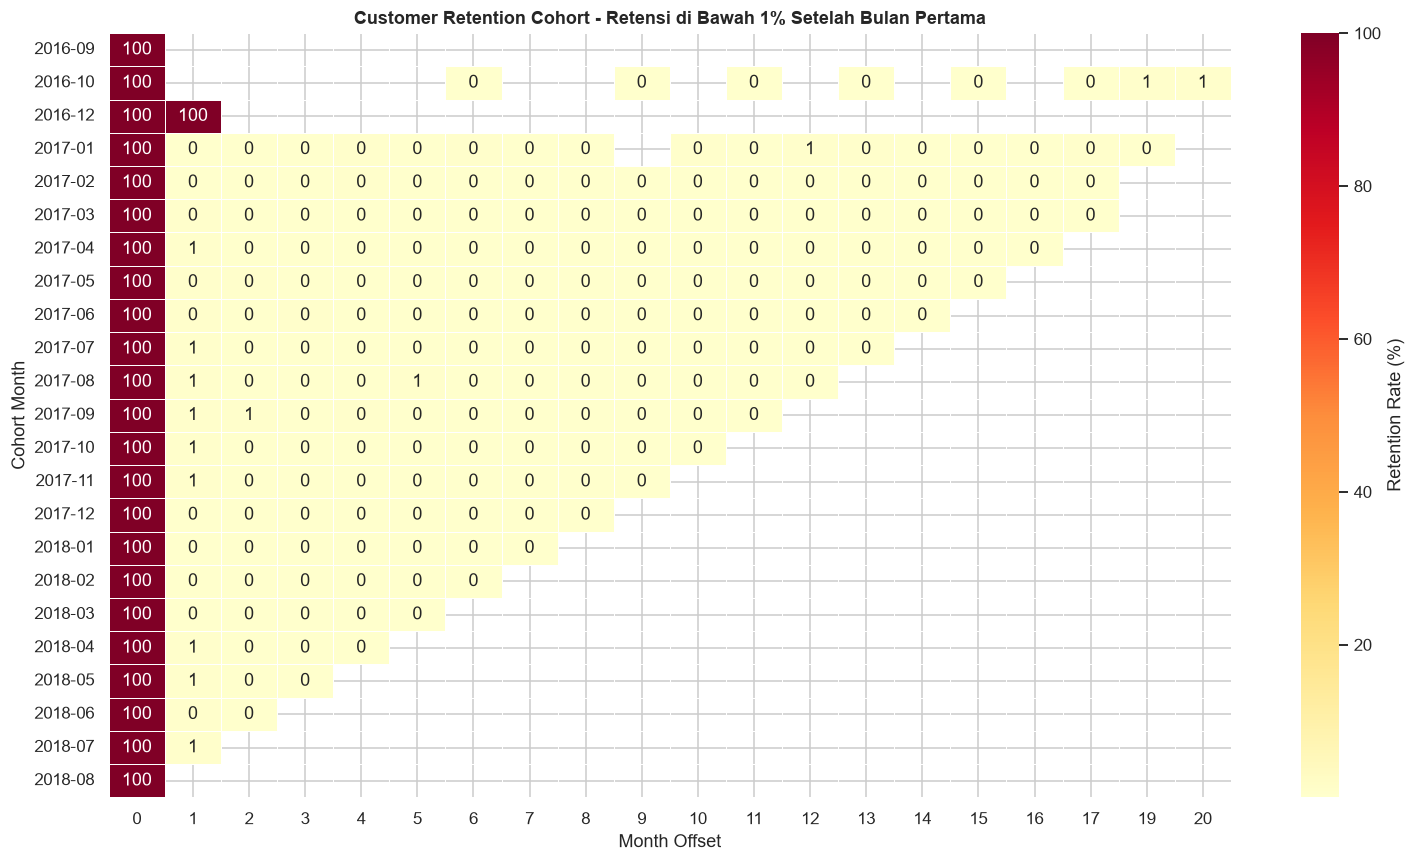

INSIGHT 5: Setelah bulan pertama, retensi hampir semua cohort hanya 0.2-0.7%.
(Cohort 2016-12 bernilai 100% karena isinya sangat sedikit customer, jadi tidak representatif.)
Artinya hampir semua customer hanya belanja sekali.
Rekomendasi: Dorong order kedua dalam 30 hari pertama (voucher repeat order, follow-up setelah pengiriman).


In [20]:
plt.figure(figsize=(14, 8))
sns.heatmap(cohort_pivot, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Retention Rate (%)'})
plt.title('Customer Retention Cohort - Retensi di Bawah 1% Setelah Bulan Pertama', fontweight='bold')
plt.ylabel('Cohort Month')
plt.xlabel('Month Offset')
plt.tight_layout()
plt.show()

print('INSIGHT 5: Setelah bulan pertama, retensi hampir semua cohort hanya 0.2-0.7%.')
print('(Cohort 2016-12 bernilai 100% karena isinya sangat sedikit customer, jadi tidak representatif.)')
print('Artinya hampir semua customer hanya belanja sekali.')
print('Rekomendasi: Dorong order kedua dalam 30 hari pertama (voucher repeat order, follow-up setelah pengiriman).')

## Model Prediktif - Random Forest

In [21]:
df_model = df_gmv_done.merge(df_reviews[['order_id', 'review_score']], on='order_id', how='left')

df_model['order_hour'] = df_model['order_purchase_timestamp'].dt.hour
df_model['order_dayofweek'] = df_model['order_purchase_timestamp'].dt.dayofweek
df_model['is_weekend'] = df_model['order_dayofweek'].isin([5, 6]).astype(int)

features = ['price', 'freight_value', 'review_score', 'is_late',
            'delivery_delay_days', 'order_hour', 'order_dayofweek', 'is_weekend']

df_model_clean = df_model[features + ['gmv']].dropna()
X = df_model_clean[features]
y = df_model_clean['gmv']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

Train: (91883, 8), Test: (22971, 8)


In [22]:
model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f'MAE: {mean_absolute_error(y_test, y_pred):.2f}')
print(f'RMSE: {mean_squared_error(y_test, y_pred)**0.5:.2f}')
print(f'R2: {r2_score(y_test, y_pred):.3f}')

MAE: 0.25
RMSE: 3.25
R2: 1.000


**Catatan keterbatasan:** target `gmv` dihitung sebagai `price + freight_value`, dan kedua kolom itu ikut jadi fitur. Model pada dasarnya hanya menjumlahkan dua fitur (target leakage), jadi R2 = 1.000 bukan bukti kemampuan prediksi. Feature importance di bawah tetap ditampilkan seperti versi lomba, tapi belum bisa dipakai untuk menyimpulkan faktor penentu GMV. Perbaikan yang wajar: keluarkan `price` dan `freight_value` dari fitur, atau pakai target lain seperti `review_score`.

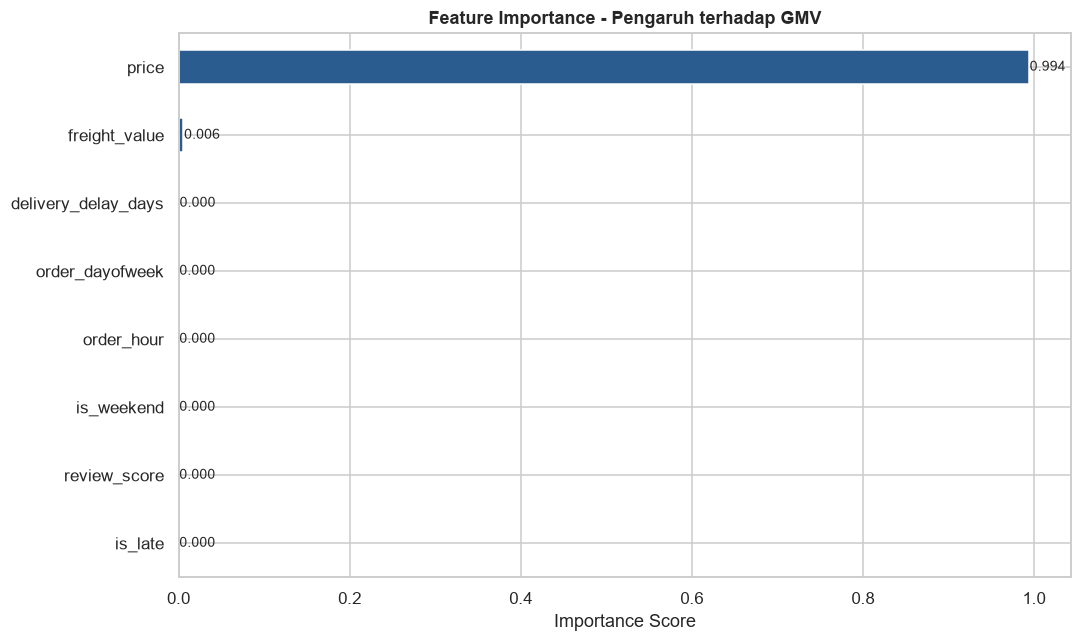

INSIGHT 6: Price paling berpengaruh, tapi ini akibat leakage (gmv = price + freight_value), bukan temuan bisnis.


In [23]:
importance = pd.Series(model.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importance.plot(kind='barh', color='#2b5c8f')
plt.title('Feature Importance - Pengaruh terhadap GMV', fontweight='bold')
plt.xlabel('Importance Score')
for i, v in enumerate(importance.values):
    plt.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print('INSIGHT 6: Price paling berpengaruh, tapi ini akibat leakage (gmv = price + freight_value), bukan temuan bisnis.')

---
# FOKUS 4: Forecasting GMV Bulanan

**Pertanyaan:** Berapa GMV bulanan yang realistis untuk beberapa bulan ke depan?

*Bagian ini ditambahkan setelah lomba untuk menjawab tujuan ketiga (forecasting).*

GMV bulanan di sini dihitung langsung dari `df_items` untuk order delivered, tanpa join ke payments. Join ke payments di bagian 5 menggandakan baris untuk order yang punya lebih dari satu pembayaran, jadi totalnya sedikit lebih besar. Rentang yang dipakai 2017-01 sampai 2018-08, karena bulan-bulan 2016 dan setelah Agustus 2018 hanya berisi sedikit order.

In [24]:
df_fc = df_orders[df_orders['order_status'] == 'delivered'][['order_id', 'order_purchase_timestamp']]
df_fc = df_fc.merge(df_items[['order_id', 'price', 'freight_value']], on='order_id', how='inner')
df_fc['gmv'] = df_fc['price'] + df_fc['freight_value']

gmv_monthly = df_fc.groupby(df_fc['order_purchase_timestamp'].dt.to_period('M'))['gmv'].sum()
gmv_monthly = gmv_monthly.loc['2017-01':'2018-08']

print(f'Total GMV delivered (tanpa join payments): {df_fc["gmv"].sum():,.0f}')
print(f'Total GMV di bagian 5 (dengan join payments): {df_gmv_done["gmv"].sum():,.0f}')
print()
print('=== GMV Bulanan ===')
print(gmv_monthly.round(0).astype(int).to_string())

Total GMV delivered (tanpa join payments): 15,419,774
Total GMV di bagian 5 (dengan join payments): 16,114,163

=== GMV Bulanan ===
order_purchase_timestamp
2017-01     127482
2017-02     271239
2017-03     414331
2017-04     390812
2017-05     566851
2017-06     490050
2017-07     566299
2017-08     645832
2017-09     701077
2017-10     751117
2017-11    1153364
2017-12     843078
2018-01    1077887
2018-02     966168
2018-03    1120598
2018-04    1132879
2018-05    1128775
2018-06    1011978
2018-07    1027807
2018-08     985492
Freq: M


In [25]:
# Evaluasi: 3 bulan terakhir jadi holdout
HORIZON = 3
t = np.arange(len(gmv_monthly)).reshape(-1, 1)
y_fc = gmv_monthly.values

t_train, t_test = t[:-HORIZON], t[-HORIZON:]
y_train_fc, y_test_fc = y_fc[:-HORIZON], y_fc[-HORIZON:]

lr_trend = LinearRegression().fit(t_train, y_train_fc)
pred_trend = lr_trend.predict(t_test)
pred_naive = np.repeat(y_train_fc[-1], HORIZON)

eval_fc = pd.DataFrame({
    'MAE': [mean_absolute_error(y_test_fc, pred_trend), mean_absolute_error(y_test_fc, pred_naive)],
    'MAPE (%)': [mean_absolute_percentage_error(y_test_fc, pred_trend) * 100,
                 mean_absolute_percentage_error(y_test_fc, pred_naive) * 100],
}, index=['Tren linear', 'Naive (bulan terakhir)'])

print(f'=== Evaluasi holdout {HORIZON} bulan ({gmv_monthly.index[-HORIZON]} s.d. {gmv_monthly.index[-1]}) ===')
print(eval_fc.round(1))
best_model = eval_fc['MAPE (%)'].idxmin()
print(f'\nModel dengan MAPE terkecil: {best_model}')

=== Evaluasi holdout 3 bulan (2018-06 s.d. 2018-08) ===
                             MAE  MAPE (%)
Tren linear             343869.9      34.2
Naive (bulan terakhir)  120348.8      12.0

Model dengan MAPE terkecil: Naive (bulan terakhir)


=== Forecast GMV ===
         Tren linear  Naive (bulan terakhir)
2018-09      1285058                  985492
2018-10      1334239                  985492
2018-11      1383420                  985492


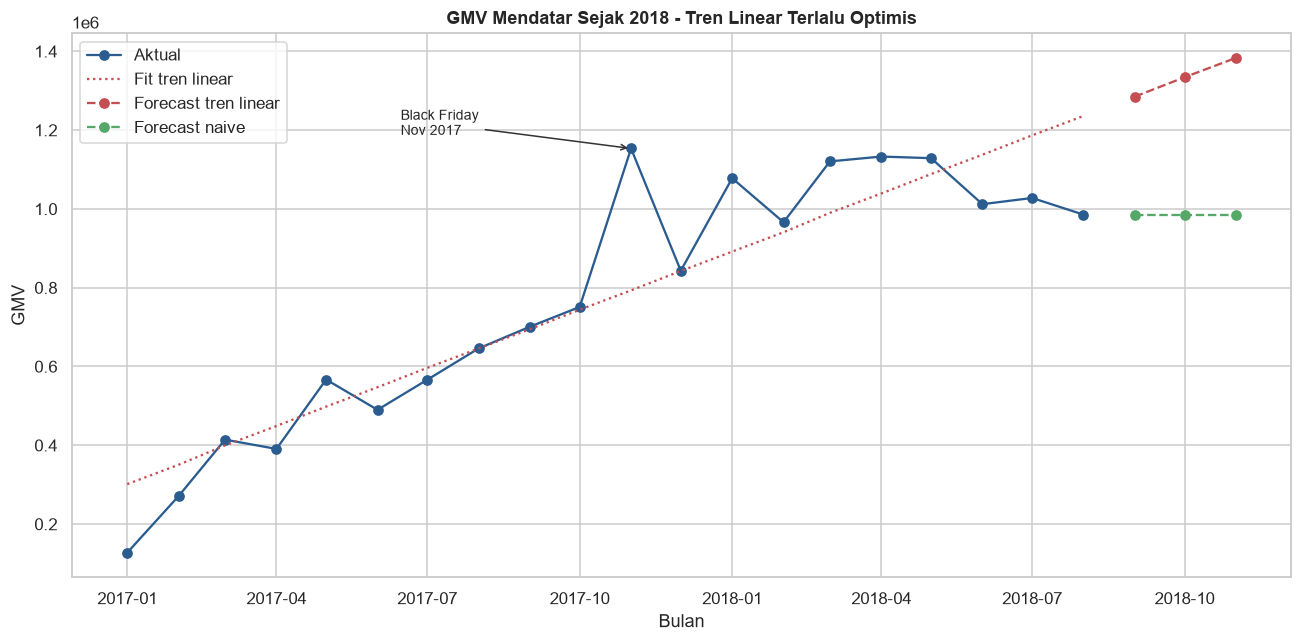

INSIGHT 7: Pada holdout, model Naive (bulan terakhir) lebih akurat (MAPE 12.0%).
GMV tumbuh cepat sepanjang 2017 lalu mendatar di 2018, sehingga tren linear menghasilkan forecast yang terlalu tinggi.
Lonjakan November 2017 (Black Friday): GMV naik 54% dari Oktober.
Rekomendasi: Pakai baseline datar di sekitar level bulan terakhir untuk target dan stok, plus buffer khusus November.


In [26]:
# Forecast 3 bulan ke depan dengan model yang di-fit ulang pada semua data
future_t = np.arange(len(gmv_monthly), len(gmv_monthly) + HORIZON).reshape(-1, 1)
future_idx = pd.period_range(gmv_monthly.index[-1] + 1, periods=HORIZON, freq='M')

lr_full = LinearRegression().fit(t, y_fc)
fc_trend = lr_full.predict(future_t)
fc_naive = np.repeat(y_fc[-1], HORIZON)

forecast = pd.DataFrame({'Tren linear': fc_trend, 'Naive (bulan terakhir)': fc_naive}, index=future_idx)
print('=== Forecast GMV ===')
print(forecast.round(0).astype(int))

x_hist = gmv_monthly.index.to_timestamp()
x_fut = future_idx.to_timestamp()

plt.figure(figsize=(12, 6))
plt.plot(x_hist, y_fc, marker='o', color='#2b5c8f', label='Aktual')
plt.plot(x_hist, lr_full.predict(t), linestyle=':', color='#c44e52', label='Fit tren linear')
plt.plot(x_fut, fc_trend, marker='o', linestyle='--', color='#c44e52', label='Forecast tren linear')
plt.plot(x_fut, fc_naive, marker='o', linestyle='--', color='#55a868', label='Forecast naive')
nov = gmv_monthly.loc['2017-11']
plt.annotate('Black Friday\nNov 2017', xy=(pd.Timestamp('2017-11-01'), nov),
             xytext=(pd.Timestamp('2017-06-15'), nov * 1.03),
             arrowprops={'arrowstyle': '->', 'color': '#333333'}, fontsize=9)
plt.title('GMV Mendatar Sejak 2018 - Tren Linear Terlalu Optimis', fontweight='bold')
plt.xlabel('Bulan')
plt.ylabel('GMV')
plt.legend()
plt.tight_layout()
plt.show()

okt = gmv_monthly.loc['2017-10']
print(f'INSIGHT 7: Pada holdout, model {best_model} lebih akurat (MAPE {eval_fc["MAPE (%)"].min():.1f}%).')
print('GMV tumbuh cepat sepanjang 2017 lalu mendatar di 2018, sehingga tren linear menghasilkan forecast yang terlalu tinggi.')
print(f'Lonjakan November 2017 (Black Friday): GMV naik {(nov / okt - 1) * 100:.0f}% dari Oktober.')
print('Rekomendasi: Pakai baseline datar di sekitar level bulan terakhir untuk target dan stok, plus buffer khusus November.')

---
# EXECUTIVE SUMMARY & REKOMENDASI BISNIS

### Temuan Utama

1. **Marketing**: Organic search sumber MQL terbesar (28.9%). Konversi tertinggi ada di paid search (12.3%) dan organic search (11.8%); email hanya 3.0% dan social 5.6% walau volume social 17.0%.
2. **Logistik**: 6.5% order delivered telat. Review order telat rata-rata 2.26 vs 4.21 untuk yang tepat waktu (selisih 1.95, ANOVA p < 0.05).
3. **RFM**: Champions punya spending rata-rata tertinggi (184), tapi selisih antar segmen tipis karena hampir semua customer hanya 1 order.
4. **Retensi**: Setelah bulan pertama, retensi hampir semua cohort hanya 0.2-0.7%.
5. **Model**: R2 = 1.000 akibat target leakage, jadi feature importance belum bisa dipakai sebagai temuan.
6. **Forecasting**: GMV bulanan mendatar sepanjang 2018. Baseline naive lebih akurat daripada tren linear pada holdout 3 bulan (lihat FOKUS 4).

### Rekomendasi Prioritas

Kolom target berisi asumsi tim, bukan hasil perhitungan di notebook ini.

| Prioritas | Rekomendasi | Dasar dari data | Target (asumsi) |
|-----------|-------------|-----------------|-----------------|
| 1 | Perbaiki ketepatan pengiriman, mulai dari order high-value | Review telat 2.26 vs tepat waktu 4.21 | Review score naik 0.5 poin |
| 2 | Dorong order kedua dalam 30 hari pertama | Retensi bulan +1 di bawah 1% | Retention naik 15% (relatif) |
| 3 | Reaktivasi segmen At Risk | 14,803 customer At Risk | Revenue naik 10% |
| 4 | Program referral untuk Champions | 14,961 customer Champions | Customer baru +20% |
| 5 | Fokus akuisisi seller di organic + paid search, evaluasi email dan social | Konversi search 11.8-12.3% vs email 3.0%, social 5.6% | Conversion naik 25% |
| 6 | Target GMV dan stok pakai baseline datar plus buffer November | Naive lebih akurat dari tren linear; lonjakan Nov 2017 | - |